<a href="https://colab.research.google.com/github/amitpaudel21/BIO_INSPIRED_SYSTEM/blob/main/1BF24CS042_BIS_LAB5_CUCKOO_SEARCH.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

INPUT DATA:
         Age        Income   Spending Profession    Region
0  24.986857  24446.942795  40.181508    Student     Rural
1  45.615149  66953.289045  88.084122    Manager     Urban
2  52.652628  48255.360262  41.292658    Retired  Suburban
3  21.137081  14549.803949  42.602957    Student     Urban
4  32.935844  67199.731328  72.735807    Manager  Suburban
Generation: 1 | Best Cost: 144.074
Generation: 2 | Best Cost: 144.074
Generation: 3 | Best Cost: 144.074
Generation: 4 | Best Cost: 137.967
Generation: 5 | Best Cost: 137.967
Generation: 6 | Best Cost: 137.967
Generation: 7 | Best Cost: 137.967
Generation: 8 | Best Cost: 137.967
Generation: 9 | Best Cost: 137.967
Generation: 10 | Best Cost: 137.967
Generation: 11 | Best Cost: 137.967
Generation: 12 | Best Cost: 137.967
Generation: 13 | Best Cost: 137.967
Generation: 14 | Best Cost: 137.967
Generation: 15 | Best Cost: 137.967
Generation: 16 | Best Cost: 137.967
Generation: 17 | Best Cost: 137.967
Generation: 18 | Best Cost: 137

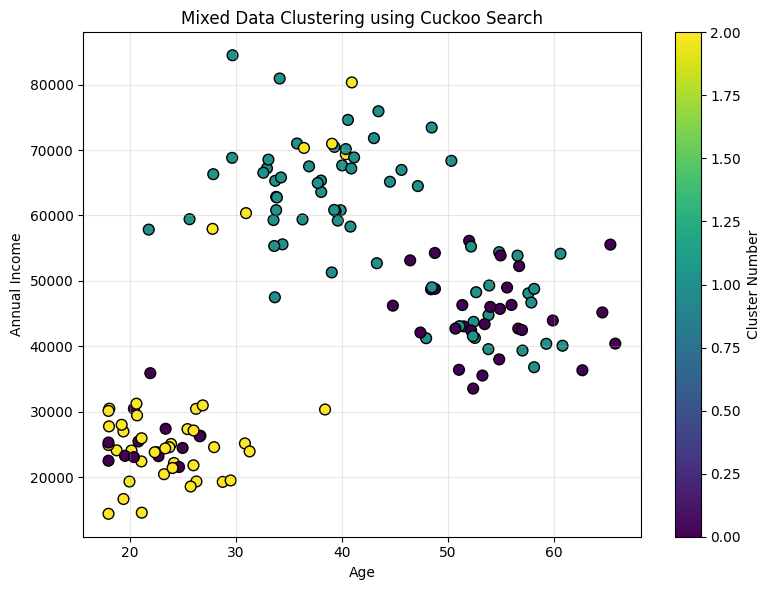

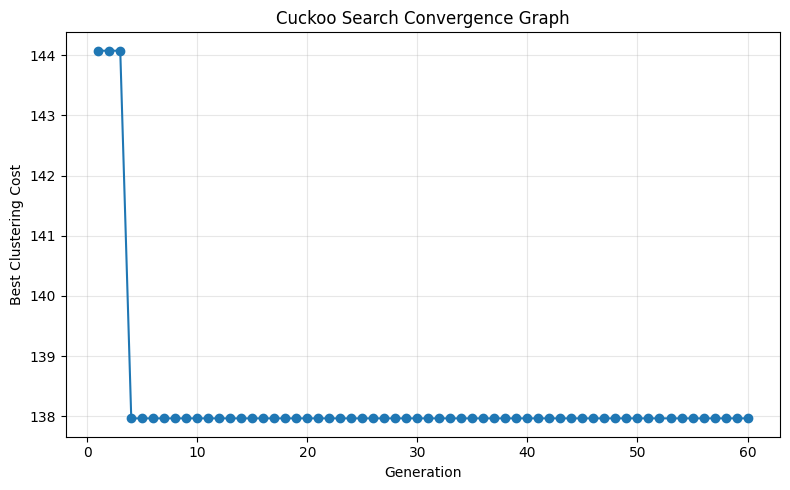

In [3]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import math

from sklearn.preprocessing import MinMaxScaler


# ==========================================
# 1. GENERATE CUSTOMER DATASET
# ==========================================

np.random.seed(42)

n = 150

data = []

for i in range(n):

    group = i % 3

    if group == 0:
        age = np.random.normal(23, 4)
        income = np.random.normal(25000, 4000)
        spending = np.random.normal(35, 8)
        profession = np.random.choice(
            ["Student", "Worker"]
        )
        region = np.random.choice(
            ["Urban", "Rural"]
        )

    elif group == 1:
        age = np.random.normal(38, 5)
        income = np.random.normal(65000, 7000)
        spending = np.random.normal(80, 8)
        profession = np.random.choice(
            ["Engineer", "Manager"]
        )
        region = np.random.choice(
            ["Urban", "Suburban"]
        )

    else:
        age = np.random.normal(55, 5)
        income = np.random.normal(45000, 6000)
        spending = np.random.normal(45, 8)
        profession = np.random.choice(
            ["Teacher", "Retired"]
        )
        region = np.random.choice(
            ["Rural", "Suburban"]
        )

    data.append([
        age, income, spending, profession, region
    ])


df = pd.DataFrame(
    data,
    columns=[
        "Age", "Income", "Spending",
        "Profession", "Region"
    ]
)

df["Age"] = df["Age"].clip(18, 75)
df["Income"] = df["Income"].clip(10000, 100000)
df["Spending"] = df["Spending"].clip(0, 100)

print("INPUT DATA:")
print(df.head())


# ==========================================
# 2. DATA PREPROCESSING
# ==========================================

num_cols = ["Age", "Income", "Spending"]
cat_cols = ["Profession", "Region"]

scaler = MinMaxScaler()

X_num = scaler.fit_transform(
    df[num_cols]
)

X_cat = df[cat_cols].to_numpy(dtype=object)

categories = [
    np.unique(X_cat[:, j])
    for j in range(len(cat_cols))
]

N = len(df)
K = 3

# Categorical attribute weight
GAMMA = 1.0


# ==========================================
# 3. MIXED DISTANCE FUNCTION
# ==========================================

def mixed_distance(x_num, x_cat, z_num, z_cat):

    numeric = np.sum(
        (x_num - z_num) ** 2
    )

    categorical = GAMMA * np.sum(
        x_cat != z_cat
    )

    return numeric + categorical


# ==========================================
# 4. CLUSTER ASSIGNMENT
# ==========================================

def assign_clusters(z_num, z_cat):

    labels = np.zeros(N, dtype=int)

    for i in range(N):

        distances = []

        for j in range(K):

            d = mixed_distance(
                X_num[i], X_cat[i],
                z_num[j], z_cat[j]
            )

            distances.append(d)

        labels[i] = np.argmin(distances)

    return labels


# ==========================================
# 5. FITNESS FUNCTION
# ==========================================

def fitness(nest):

    z_num, z_cat = nest

    labels = assign_clusters(
        z_num, z_cat
    )

    cost = 0.0

    for i in range(N):

        j = labels[i]

        cost += mixed_distance(
            X_num[i], X_cat[i],
            z_num[j], z_cat[j]
        )

    return cost


# ==========================================
# 6. LEVY FLIGHT (MANTE GNA METHOD)
# ==========================================

def levy_flight(beta=1.5):

    sigma = (
        math.gamma(1 + beta)
        * math.sin(math.pi * beta / 2)
        /
        (
            math.gamma((1 + beta) / 2)
            * beta
            * 2 ** ((beta - 1) / 2)
        )
    ) ** (1 / beta)

    u = np.random.normal(0, sigma)
    v = np.random.normal(0, 1)

    return u / (
        abs(v) ** (1 / beta) + 1e-10
    )


# ==========================================
# 7. INITIALIZE CUCKOO NESTS
# ==========================================

NESTS = 12
MAX_GEN = 60
PA = 0.25
ALPHA = 0.05

nests = []

for _ in range(NESTS):

    indices = np.random.choice(
        N, K, replace=False
    )

    nest = (
        X_num[indices].copy(),
        X_cat[indices].copy()
    )

    nests.append(nest)


scores = np.array([
    fitness(nest) for nest in nests
])

best_idx = np.argmin(scores)

best_nest = (
    nests[best_idx][0].copy(),
    nests[best_idx][1].copy()
)

best_cost = scores[best_idx]

history = []


# ==========================================
# 8. LOCAL SEARCH USING LEVY FLIGHT
# ==========================================

def local_search(current, best):

    current_num, current_cat = current
    best_num, best_cat = best

    new_num = current_num.copy()
    new_cat = current_cat.copy()

    for i in range(K):

        step = levy_flight()

        # Numeric prototype update
        new_num[i] = (
            current_num[i]
            + ALPHA * step
            * np.abs(current_num[i] - best_num[i])
        )

        new_num[i] = np.clip(
            new_num[i], 0, 1
        )

        # Categorical prototype update
        for j in range(len(cat_cols)):

            choices = [
                current_cat[i, j],
                best_cat[i, j]
            ]

            new_cat[i, j] = np.random.choice(
                choices
            )

    return new_num, new_cat


# ==========================================
# 9. GLOBAL SEARCH / ABANDONMENT
# ==========================================

def global_search(worst, nest1, nest2):

    worst_num, worst_cat = worst
    num1, cat1 = nest1
    num2, cat2 = nest2

    new_num = worst_num.copy()
    new_cat = worst_cat.copy()

    epsilon = np.random.random()

    for i in range(K):

        # Numeric global update
        new_num[i] = (
            worst_num[i]
            + epsilon * np.abs(
                num1[i] - num2[i]
            )
        )

        new_num[i] = np.clip(
            new_num[i], 0, 1
        )

        # Categorical global update
        for j in range(len(cat_cols)):

            choices = [
                worst_cat[i, j],
                cat1[i, j],
                cat2[i, j]
            ]

            new_cat[i, j] = np.random.choice(
                choices
            )

    return new_num, new_cat


# ==========================================
# 10. CUCKOO SEARCH OPTIMIZATION
# ==========================================

for generation in range(MAX_GEN):

    for i in range(NESTS):

        # Generate cuckoo solution
        new_nest = local_search(
            nests[i], best_nest
        )

        new_cost = fitness(new_nest)

        # Compare with randomly selected nest
        j = np.random.randint(NESTS)

        if new_cost < scores[j]:

            nests[j] = new_nest
            scores[j] = new_cost

    # Global search and nest abandonment
    worst_indices = np.argsort(scores)[
        -max(1, int(PA * NESTS)):
    ]

    for j in worst_indices:

        candidates = np.random.choice(
            NESTS, 2, replace=False
        )

        new_nest = global_search(
            nests[j],
            nests[candidates[0]],
            nests[candidates[1]]
        )

        new_cost = fitness(new_nest)

        if new_cost < scores[j]:

            nests[j] = new_nest
            scores[j] = new_cost

    # Update global best
    best_idx = np.argmin(scores)

    if scores[best_idx] < best_cost:

        best_cost = scores[best_idx]

        best_nest = (
            nests[best_idx][0].copy(),
            nests[best_idx][1].copy()
        )

    history.append(best_cost)

    print(
        "Generation:", generation + 1,
        "| Best Cost:", round(best_cost, 4)
    )


# ==========================================
# 11. FINAL CLUSTERING
# ==========================================

best_num, best_cat = best_nest

labels = assign_clusters(
    best_num, best_cat
)

df["Cluster"] = labels

print("\nFINAL CLUSTERING OUTPUT:")
print(df.head(15))

print("\nCLUSTER SIZES:")
print(df["Cluster"].value_counts().sort_index())

print("\nFINAL CLUSTERING COST:")
print(round(best_cost, 4))


# ==========================================
# 12. CLUSTER VISUALIZATION
# ==========================================

plt.figure(figsize=(8, 6))

plt.scatter(
    df["Age"],
    df["Income"],
    c=labels,
    cmap="viridis",
    s=60,
    edgecolors="black"
)

plt.xlabel("Age")
plt.ylabel("Annual Income")

plt.title(
    "Mixed Data Clustering using Cuckoo Search"
)

plt.colorbar(label="Cluster Number")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# ==========================================
# 13. CONVERGENCE GRAPH
# ==========================================

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, MAX_GEN + 1),
    history,
    marker="o"
)

plt.xlabel("Generation")
plt.ylabel("Best Clustering Cost")

plt.title(
    "Cuckoo Search Convergence Graph"
)

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()
